# Exercício 1 — Valores Ausentes
**Dataset:** Melbourne Housing Snapshot (`melb_data.csv`)

Objetivo: entender onde faltam dados, quanto falta e decidir o que fazer com isso antes de qualquer análise de preço.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import time
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [2]:
# CARREGAMENTO DOS DADOS
df = pd.read_csv('melb_data.csv')
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,"1,480,000.00",S,Biggin,3/12/2016,2.50,"3,067.00",2.00,1.00,1.00,202.00,NaN,NaN,Yarra,-37.80,145.00,Northern Metropolitan,"4,019.00"
1,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,4/02/2016,2.50,"3,067.00",2.00,1.00,0.00,156.00,79.00,"1,900.00",Yarra,-37.81,144.99,Northern Metropolitan,"4,019.00"
2,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,4/03/2017,2.50,"3,067.00",3.00,2.00,0.00,134.00,150.00,"1,900.00",Yarra,-37.81,144.99,Northern Metropolitan,"4,019.00"
3,Abbotsford,40 Federation La,3,h,"850,000.00",PI,Biggin,4/03/2017,2.50,"3,067.00",3.00,2.00,1.00,94.00,NaN,NaN,Yarra,-37.80,145.00,Northern Metropolitan,"4,019.00"
4,Abbotsford,55a Park St,4,h,"1,600,000.00",VB,Nelson,4/06/2016,2.50,"3,067.00",3.00,1.00,2.00,120.00,142.00,"2,014.00",Yarra,-37.81,144.99,Northern Metropolitan,"4,019.00"


## Diagnóstico inicial

In [3]:
# DIAGNÓSTICO INICIAL
print('Dimensões:', df.shape)
print()
df.info()

Dimensões: (13580, 21)

<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Lattitude      13580 non-null  float6

In [4]:
# total de ausentes por coluna (todas as colunas, inclusive as que não têm nenhum)
df.isna().sum()

Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
dtype: int64

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,"13,580.00",2.94,0.96,1.00,2.00,3.00,3.00,10.00
Price,"13,580.00","1,075,684.08","639,310.72","85,000.00","650,000.00","903,000.00","1,330,000.00","9,000,000.00"
Distance,"13,580.00",10.14,5.87,0.00,6.10,9.20,13.00,48.10
Postcode,"13,580.00","3,105.30",90.68,"3,000.00","3,044.00","3,084.00","3,148.00","3,977.00"
Bedroom2,"13,580.00",2.91,0.97,0.00,2.00,3.00,3.00,20.00
Bathroom,"13,580.00",1.53,0.69,0.00,1.00,1.00,2.00,8.00
Car,"13,518.00",1.61,0.96,0.00,1.00,2.00,2.00,10.00
Landsize,"13,580.00",558.42,"3,990.67",0.00,177.00,440.00,651.00,"433,014.00"
BuildingArea,"7,130.00",151.97,541.01,0.00,93.00,126.00,174.00,"44,515.00"
YearBuilt,"8,205.00","1,964.68",37.27,"1,196.00","1,940.00","1,970.00","1,999.00","2,018.00"


Primeiras impressões olhando o `info()` e o `describe()`:

- São **13.580 linhas e 21 colunas**. Só 4 colunas têm valores faltando: `BuildingArea`, `YearBuilt`, `CouncilArea` e `Car`.
- `Date` veio como texto, mas isso não atrapalha aqui. Só converti quando precisei olhar o ano.
- Já dá para ver umas coisas estranhas que não são exatamente "ausentes", mas chamam atenção: `YearBuilt` com mínimo **1196** (difícil ter casa do século XII em Melbourne), `BuildingArea` e `Landsize` com mínimo **0** e máximos absurdos (44.515 m² de área construída?). Não é o foco desse exercício, mas anotei porque isso afeta a escolha entre média e mediana.

## Resumo de valores ausentes (quantidade e %)

In [6]:
# RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
ausentes = df.isna().sum()
resumo_ausentes = pd.DataFrame({
    'qtd_ausentes': ausentes,
    'pct_ausentes': (ausentes / len(df) * 100).round(2)
})
resumo_ausentes = resumo_ausentes[resumo_ausentes['qtd_ausentes'] > 0].sort_values('qtd_ausentes', ascending=False)
resumo_ausentes

,qtd_ausentes,pct_ausentes
BuildingArea,6450,47.50
YearBuilt,5375,39.58
CouncilArea,1369,10.08
Car,62,0.46


Quase metade dos imóveis (**47,5%**) não tem `BuildingArea` e quase 40% não tem `YearBuilt`. `CouncilArea` falta em uns 10% e `Car` é praticamente irrelevante (62 linhas, menos de 0,5%).

## Visualização do padrão de ausência

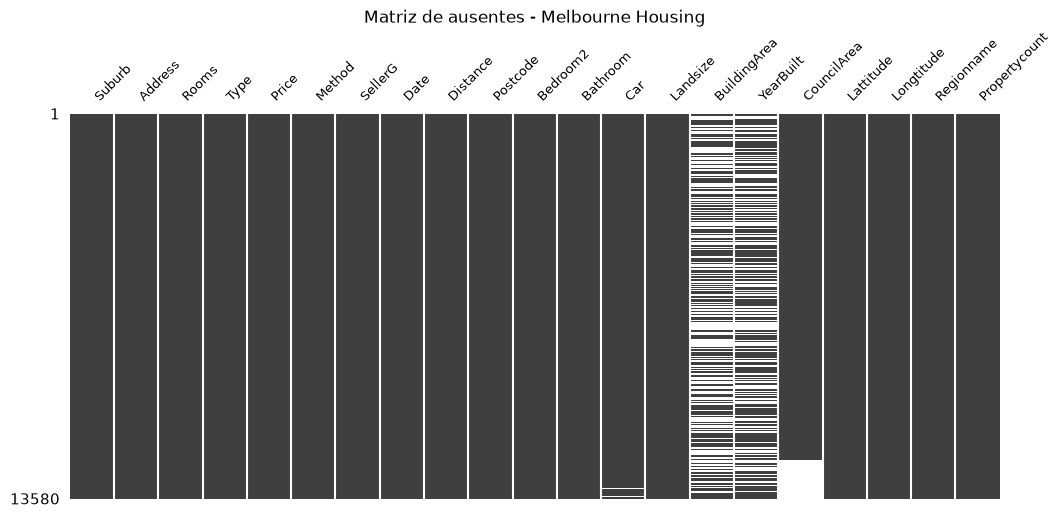

In [7]:
# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA
# matriz: cada linha branca é um valor faltando
msno.matrix(df, figsize=(12, 5), fontsize=9, sparkline=False)
plt.title('Matriz de ausentes - Melbourne Housing', fontsize=12)
plt.show()

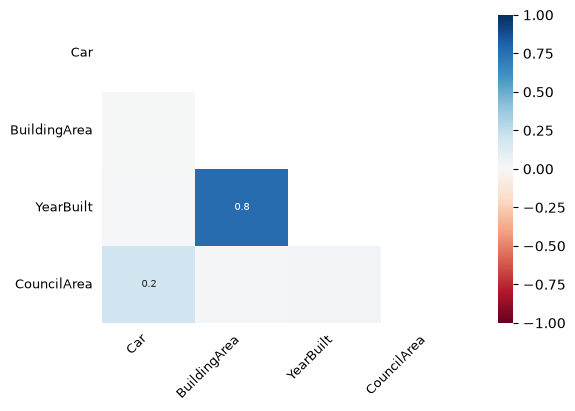

In [8]:
# heatmap de correlação da ausência (1 = sempre faltam juntas)
msno.heatmap(df, figsize=(6, 4), fontsize=9)
plt.show()

In [9]:
# conferindo numericamente se BuildingArea e YearBuilt faltam juntas
falta_ba = df['BuildingArea'].isna()
falta_yb = df['YearBuilt'].isna()
print('Faltam BuildingArea:', falta_ba.sum())
print('Faltam YearBuilt:', falta_yb.sum())
print('Faltam as duas na mesma linha:', (falta_ba & falta_yb).sum())
print(f'-> {(falta_ba & falta_yb).sum() / falta_yb.sum():.0%} das linhas sem YearBuilt também estão sem BuildingArea')
print()
print('Linhas sem nenhum valor faltando:', df.dropna().shape[0], f'({df.dropna().shape[0]/len(df):.0%} do total)')

Faltam BuildingArea: 6450
Faltam YearBuilt: 5375
Faltam as duas na mesma linha: 5103
-> 95% das linhas sem YearBuilt também estão sem BuildingArea

Linhas sem nenhum valor faltando: 6196 (46% do total)


**O que eu observei:**

- Sim, as ausências estão concentradas em poucas colunas. As outras 17 estão completas.
- `BuildingArea` e `YearBuilt` claramente faltam **juntas**. Na matriz dá para ver as faixas brancas alinhadas, e o heatmap mostra correlação de 0,8 entre as duas. Conferindo na mão: 95% das linhas sem `YearBuilt` também estão sem `BuildingArea`. Parece que essas duas informações vinham da mesma fonte (provavelmente o anúncio do imóvel) e, quando a fonte não tinha, faltavam as duas.
- Só 46% das linhas estão 100% completas. Ou seja, um `dropna()` sem pensar jogaria fora mais da metade da base.

In [10]:
# a ausência tem relação com alguma outra variável? (ex.: tipo de imóvel e preço)
tab = df.assign(falta_BuildingArea=falta_ba).groupby('falta_BuildingArea').agg(
    qtd=('Price', 'size'), preco_medio=('Price', 'mean'), preco_mediano=('Price', 'median'))
print(tab)
print()
print('% de BuildingArea ausente por tipo de imóvel (h=casa, u=apartamento, t=townhouse):')
print((df.groupby('Type')['BuildingArea'].apply(lambda s: s.isna().mean()) * 100).round(1))
print()
print('% de CouncilArea ausente por ano da venda:')
ano = pd.to_datetime(df['Date'], dayfirst=True).dt.year
print((df['CouncilArea'].isna().groupby(ano).mean() * 100).round(1))

                     qtd  preco_medio  preco_mediano
falta_BuildingArea                                  
False               7130 1,079,922.73     895,000.00
True                6450 1,070,998.57     917,000.00

% de BuildingArea ausente por tipo de imóvel (h=casa, u=apartamento, t=townhouse):
Type
h   48.60
t   38.40
u   47.50
Name: BuildingArea, dtype: float64

% de CouncilArea ausente por ano da venda:
Date
2016    0.00
2017   18.90
Name: CouncilArea, dtype: float64


Isso aqui me surpreendeu um pouco:

- O preço médio e mediano é praticamente o mesmo com ou sem `BuildingArea`, e a proporção de ausentes é parecida entre casas e apartamentos. Então a falta de `BuildingArea` **não parece** estar ligada ao preço. Isso é uma boa notícia, porque imputar ou remover não deve enviesar tanto a análise de preço.
- Já o `CouncilArea` tem um padrão bem claro: **em 2016 não falta nenhum, em 2017 falta quase 19%**. Isso não é aleatório. Algo mudou na coleta em 2017 (talvez o site de origem parou de informar o conselho municipal). É o tipo de coisa que só aparece quando a gente cruza a ausência com outra coluna.

## Estratégia 1 — Remoção

**Decisão:** removi **colunas** para `BuildingArea` e `YearBuilt`, e **linhas** para `Car` e `CouncilArea`.

- Remover linhas por causa de `BuildingArea`/`YearBuilt` custaria mais de 50% da base. Não compensa.
- Já em `Car` e `CouncilArea` o volume é pequeno o suficiente para remover as linhas e ainda ficar com cerca de 90% dos dados.

O ponto fraco dessa escolha é que eu perco duas variáveis que, intuitivamente, são importantes para preço (tamanho e idade do imóvel).

In [11]:
# ESTRATÉGIA 1 — REMOÇÃO
df_remocao = df.copy()

# BuildingArea (47%) e YearBuilt (40%): remover as LINHAS jogaria fora mais da metade da base,
# então aqui eu removo as COLUNAS.
df_remocao = df_remocao.drop(columns=['BuildingArea', 'YearBuilt'])

# Car (0,46%) e CouncilArea (10%): aí sim removo as linhas, porque sobra a grande maioria.
df_remocao = df_remocao.dropna(subset=['Car', 'CouncilArea'])

print('Original :', df.shape)
print('Remoção  :', df_remocao.shape)
print(f'Linhas perdidas: {len(df) - len(df_remocao)} ({(len(df) - len(df_remocao)) / len(df):.1%})')
print('Ausentes restantes:', df_remocao.isna().sum().sum())

# só para comparação: o que aconteceria com um dropna() "no automático"
df_dropna_geral = df.dropna()
print()
print('Se eu fizesse df.dropna() direto:', df_dropna_geral.shape, f'-> perderia {1 - len(df_dropna_geral)/len(df):.0%} das linhas')

Original : (13580, 21)
Remoção  : (12211, 19)
Linhas perdidas: 1369 (10.1%)
Ausentes restantes: 0

Se eu fizesse df.dropna() direto: (6196, 21) -> perderia 54% das linhas


## Estratégia 2 — Imputação

**Decisão:**
- `BuildingArea`, `YearBuilt` e `Car` → **mediana**. São colunas numéricas com cauda longa e valores extremos (vide o 44.515 m²), então a média seria puxada para cima. Para `Car` a mediana ainda tem a vantagem de dar um número inteiro (2 vagas), enquanto a média daria 1,61 vaga, que não existe.
- `CouncilArea` → é categórica, então seria moda. Mas em vez de usar a moda geral (que colocaria todo mundo no mesmo conselho), usei a **moda do subúrbio**: cada subúrbio pertence a um conselho, então o próprio dado já "sabe" a resposta na maioria dos casos. O que sobrou virou a categoria `Desconhecido`.
- Antes de preencher, criei colunas `*_ausente` (0/1) para não perder a informação de que aquele valor não existia originalmente.

In [12]:
# ESTRATÉGIA 2 — IMPUTAÇÃO
df_imputacao = df.copy()

# antes de imputar, guardo a informação de que o valor estava faltando
for col in ['BuildingArea', 'YearBuilt', 'Car', 'CouncilArea']:
    df_imputacao[f'{col}_ausente'] = df_imputacao[col].isna().astype(int)

# numéricas -> mediana (as distribuições são assimétricas e têm valores extremos)
medianas = df[['BuildingArea', 'YearBuilt', 'Car']].median()
print('Medianas usadas na imputação:')
print(medianas)
df_imputacao[['BuildingArea', 'YearBuilt', 'Car']] = df_imputacao[['BuildingArea', 'YearBuilt', 'Car']].fillna(medianas)

# CouncilArea é categórica. Em vez de usar a moda geral, uso a moda do próprio subúrbio
# (um subúrbio pertence a um conselho municipal, então faz mais sentido).
moda_por_suburbio = (df.dropna(subset=['CouncilArea'])
                       .groupby('Suburb')['CouncilArea']
                       .agg(lambda s: s.mode().iloc[0]))
df_imputacao['CouncilArea'] = df_imputacao['CouncilArea'].fillna(df_imputacao['Suburb'].map(moda_por_suburbio))
print()
print('CouncilArea ainda sem valor depois da moda por subúrbio:', df_imputacao['CouncilArea'].isna().sum())
# o que sobrar (subúrbio que nunca teve conselho registrado) vira uma categoria própria
df_imputacao['CouncilArea'] = df_imputacao['CouncilArea'].fillna('Desconhecido')

print('Dimensões:', df_imputacao.shape)
print('Ausentes restantes:', df_imputacao.isna().sum().sum())

Medianas usadas na imputação:
BuildingArea     126.00
YearBuilt      1,970.00
Car                2.00
dtype: float64

CouncilArea ainda sem valor depois da moda por subúrbio: 7
Dimensões: (13580, 25)
Ausentes restantes: 0


## Comparação entre as estratégias

In [13]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
print('Linhas -> original:', len(df), '| remoção:', len(df_remocao), '| imputação:', len(df_imputacao))

def resumo(serie):
    return pd.Series({'linhas_validas': serie.notna().sum(), 'media': serie.mean(),
                      'mediana': serie.median(), 'desvio': serie.std()})

linhas = []
for col in ['BuildingArea', 'YearBuilt', 'Car']:
    linhas.append(resumo(df[col]).rename(f'{col} | original'))
    if col in df_remocao:
        linhas.append(resumo(df_remocao[col]).rename(f'{col} | remoção'))
    else:
        linhas.append(pd.Series({'linhas_validas': 0}, name=f'{col} | remoção (coluna descartada)'))
    linhas.append(resumo(df_imputacao[col]).rename(f'{col} | imputação'))
# Price não foi tratado, mas a remoção de linhas pode ter mudado a distribuição dele
linhas.append(resumo(df['Price']).rename('Price | original'))
linhas.append(resumo(df_remocao['Price']).rename('Price | remoção'))
pd.DataFrame(linhas)

Linhas -> original: 13580 | remoção: 12211 | imputação: 13580


,linhas_validas,media,mediana,desvio
BuildingArea | original,"7,130.00",151.97,126.00,541.01
BuildingArea | remoção (coluna descartada),0.00,NaN,NaN,NaN
BuildingArea | imputação,"13,580.00",139.63,126.00,392.22
YearBuilt | original,"8,205.00","1,964.68","1,970.00",37.27
YearBuilt | remoção (coluna descartada),0.00,NaN,NaN,NaN
YearBuilt | imputação,"13,580.00","1,966.79","1,970.00",29.09
Car | original,"13,518.00",1.61,2.00,0.96
Car | remoção,"12,211.00",1.57,1.00,0.95
Car | imputação,"13,580.00",1.61,2.00,0.96
Price | original,"13,580.00","1,075,684.08","903,000.00","639,310.72"


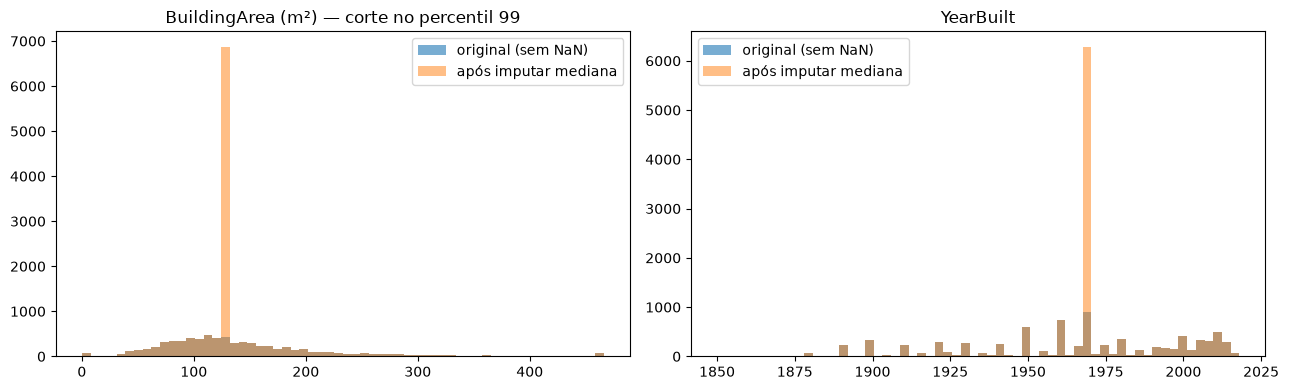

In [14]:
# distribuição antes x depois (BuildingArea e YearBuilt). Cortei a cauda do BuildingArea para dar para ver alguma coisa.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

lim = df['BuildingArea'].quantile(0.99)
axes[0].hist(df['BuildingArea'].dropna().clip(upper=lim), bins=60, alpha=0.6, label='original (sem NaN)')
axes[0].hist(df_imputacao['BuildingArea'].clip(upper=lim), bins=60, alpha=0.5, label='após imputar mediana')
axes[0].set_title('BuildingArea (m²) — corte no percentil 99')
axes[0].legend()

axes[1].hist(df['YearBuilt'].dropna().clip(lower=1850), bins=60, alpha=0.6, label='original (sem NaN)')
axes[1].hist(df_imputacao['YearBuilt'].clip(lower=1850), bins=60, alpha=0.5, label='após imputar mediana')
axes[1].set_title('YearBuilt')
axes[1].legend()
plt.tight_layout()
plt.show()

In [15]:
# a remoção de linhas mudou a proporção de tipos de imóvel ou regiões?
comp = pd.DataFrame({
    'original_%': df['Regionname'].value_counts(normalize=True) * 100,
    'remocao_%': df_remocao['Regionname'].value_counts(normalize=True) * 100,
}).round(2)
comp['diferenca'] = comp['remocao_%'] - comp['original_%']
comp

,original_%,remocao_%,diferenca
Regionname,,,
Southern Metropolitan,34.57,35.54,0.97
Northern Metropolitan,28.65,29.10,0.45
Western Metropolitan,21.71,21.85,0.14
Eastern Metropolitan,10.83,10.06,-0.77
South-Eastern Metropolitan,3.31,2.66,-0.65
Eastern Victoria,0.39,0.36,-0.03
Northern Victoria,0.30,0.21,-0.09
Western Victoria,0.24,0.20,-0.04


**Resumo da comparação:**

| | Original | Remoção | Imputação |
|---|---|---|---|
| Linhas | 13.580 | 12.211 (-10,1%) | 13.580 |
| Colunas | 21 | 19 | 25 (com as flags) |
| `BuildingArea` | 7.130 válidos | coluna descartada | 13.580 |

O que eu tiro disso:

- **Na imputação, a mediana fica igual mas a média e o desvio mudam.** A média de `BuildingArea` caiu de 152 para 139,6 e o desvio caiu de 541 para 392. O histograma mostra o motivo: aparece um "pico" gigante exatamente em 126 m². Metade das casas sem área ganhou o mesmo valor, o que reduz artificialmente a variabilidade. O mesmo acontece em `YearBuilt` (pico em 1970, desvio caiu de 37 para 29).
- **Na remoção, um detalhe que eu não esperava:** a mediana de `Car` caiu de 2 para 1. Como as linhas removidas são quase todas as de 2017 sem `CouncilArea`, eu acabei tirando mais imóveis de certas regiões (dá para ver na tabela que o *Southern Metropolitan* ganhou peso e o *South-Eastern* perdeu). A média de `Price` também caiu uns 12 mil dólares. Não é uma mudança enorme, mas mostra que remover linhas **não é neutro** quando a ausência não é aleatória.
- Nenhuma das duas é perfeita. Para uma análise de preço eu iria pela imputação com as flags, porque mantém todas as linhas e a variável de área, mas tomando cuidado ao interpretar a variância.

## Respostas às perguntas de reflexão

In [16]:
# apoio para a reflexão: média x mediana em colunas assimétricas
for col in ['Price', 'Landsize', 'BuildingArea']:
    s = df[col]
    print(f'{col:13s} média = {s.mean():>12,.1f} | mediana = {s.median():>12,.1f} | máx = {s.max():>12,.1f} | assimetria = {s.skew():.1f}')

Price         média =  1,075,684.1 | mediana =    903,000.0 | máx =  9,000,000.0 | assimetria = 2.2
Landsize      média =        558.4 | mediana =        440.0 | máx =    433,014.0 | assimetria = 95.2
BuildingArea  média =        152.0 | mediana =        126.0 | máx =     44,515.0 | assimetria = 77.7


**1. Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada? De que essa decisão depende?**

Não tem uma regra fixa, e foi isso que mais ficou claro fazendo o exercício. Depende principalmente de três coisas:

- **Da importância da coluna para a pergunta.** `BuildingArea` está perto de 50% vazia, mas para quem quer prever preço ela é provavelmente uma das variáveis mais importantes. Descartar de cara seria jogar fora informação valiosa que existe para a outra metade.
- **Do motivo da ausência.** Se falta de forma aleatória, imputar é mais tranquilo. Se falta por algum motivo (como o `CouncilArea` que só falta em 2017), imputar com um valor único pode criar um padrão falso.
- **De ter como imputar bem.** Com mais da metade faltando, uma mediana simples vira o valor mais comum da coluna (vi isso no histograma). Se dá para usar outras colunas para estimar (KNN, regressão, moda por grupo), imputar faz mais sentido. Se não, e a coluna não é essencial, eu descartaria.

Na prática eu tentaria as duas coisas e veria qual dá resultado melhor no modelo ou na análise.

**2. Para colunas como `Price` ou `Landsize`, média e mediana dariam valores de imputação parecidos? Qual seria mais segura, e por quê?**

Não dariam. No `Price` a média é 1,076 milhão e a mediana é 903 mil, uma diferença de mais de 170 mil dólares. No `Landsize` é pior: média de 558 m² contra mediana de 440 m², porque existe um terreno de 433 mil m² puxando a média (a assimetria dá 95!). A **mediana é mais segura** porque não é afetada por esses poucos valores enormes. Imputar pela média colocaria nos imóveis sem informação um valor que é maior do que o da maioria dos imóveis reais.

**3. Em que situação o fato de um valor estar ausente é, por si só, uma informação útil?**

Quando a ausência tem um motivo. Aqui mesmo apareceu um exemplo: `CouncilArea` só falta em vendas de 2017, então a ausência basicamente "conta" o período da venda. Outros exemplos que consigo pensar: um imóvel sem `YearBuilt` pode ser um imóvel muito antigo em que ninguém sabe a data; um anúncio sem `BuildingArea` pode indicar um vendedor menos cuidadoso ou um imóvel vendido "para reforma". Em formulários, quem deixa a renda em branco costuma ter um perfil diferente de quem preenche. Por isso criei as colunas `*_ausente` antes de imputar: se a ausência tiver poder preditivo, o modelo consegue usar.

## Desafio — KNNImputer

O `KNNImputer` preenche cada valor faltante olhando os *k* imóveis mais parecidos (pelas outras colunas) e tirando a média deles. Usei `Rooms`, `Bathroom`, `Bedroom2`, `Landsize`, `Distance` e `Price` como base para encontrar os vizinhos, com *k* = 5. Tive que padronizar as colunas antes, senão a distância seria dominada por `Price` (que está na casa dos milhões).

In [17]:
# DESAFIO — KNNImputer na coluna BuildingArea
# uso como "vizinhança" colunas numéricas que não têm ausentes e que têm relação com o tamanho da construção
cols_knn = ['Rooms', 'Bathroom', 'Bedroom2', 'Landsize', 'Distance', 'Price', 'BuildingArea']
base = df[cols_knn].copy()

# o KNN usa distância, então precisa escalar (senão Price e Landsize dominam tudo)
scaler = StandardScaler()
base_esc = pd.DataFrame(scaler.fit_transform(base), columns=cols_knn)  # o scaler ignora NaN no fit

inicio = time.time()
imp = KNNImputer(n_neighbors=5)
base_imp = pd.DataFrame(imp.fit_transform(base_esc), columns=cols_knn)
tempo_knn = time.time() - inicio

base_imp = pd.DataFrame(scaler.inverse_transform(base_imp), columns=cols_knn)
df_knn = df.copy()
df_knn['BuildingArea'] = base_imp['BuildingArea'].values

inicio = time.time()
_ = df['BuildingArea'].fillna(df['BuildingArea'].median())
tempo_mediana = time.time() - inicio

print(f'Tempo KNN: {tempo_knn:.2f}s | tempo mediana: {tempo_mediana:.4f}s')
print()
pd.DataFrame({
    'original (sem NaN)': resumo(df['BuildingArea']),
    'mediana': resumo(df_imputacao['BuildingArea']),
    'KNN (k=5)': resumo(df_knn['BuildingArea']),
}).T

Tempo KNN: 3.57s | tempo mediana: 0.0000s



,linhas_validas,media,mediana,desvio
original (sem NaN),"7,130.00",151.97,126.00,541.01
mediana,"13,580.00",139.63,126.00,392.22
KNN (k=5),"13,580.00",149.52,125.20,430.18


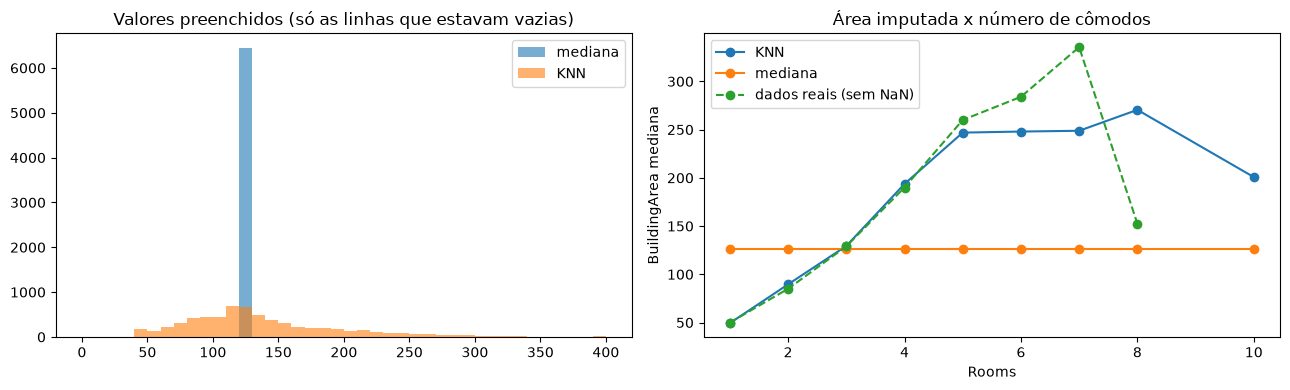

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lim = 400
faltavam = df['BuildingArea'].isna()
axes[0].hist(df_imputacao.loc[faltavam, 'BuildingArea'], bins=40, range=(0, lim), alpha=0.6, label='mediana')
axes[0].hist(df_knn.loc[faltavam, 'BuildingArea'], bins=40, range=(0, lim), alpha=0.6, label='KNN')
axes[0].set_title('Valores preenchidos (só as linhas que estavam vazias)')
axes[0].legend()

# KNN respeita a relação com o número de quartos, a mediana não
axes[1].plot(df_knn.loc[faltavam].groupby('Rooms')['BuildingArea'].median(), marker='o', label='KNN')
axes[1].plot(df_imputacao.loc[faltavam].groupby('Rooms')['BuildingArea'].median(), marker='o', label='mediana')
axes[1].plot(df.groupby('Rooms')['BuildingArea'].median(), marker='o', linestyle='--', label='dados reais (sem NaN)')
axes[1].set_xlabel('Rooms')
axes[1].set_ylabel('BuildingArea mediana')
axes[1].set_title('Área imputada x número de cômodos')
axes[1].legend()
plt.tight_layout()
plt.show()

**O que muda:**

- Com a mediana, todo imóvel sem área ganha 126 m², seja uma quitinete de 1 quarto ou uma casa de 6. No gráfico da direita, a linha da mediana é reta.
- Com o KNN, os valores preenchidos acompanham o número de cômodos. Até 5 cômodos a curva fica praticamente colada na dos dados reais; acima disso o KNN subestima um pouco, porque existem poucos imóveis tão grandes para servir de "vizinho". A distribuição dos valores preenchidos fica espalhada e não concentrada num pico só. A média geral (149,5) ficou bem mais perto da original (152) e o desvio caiu menos.

**O custo:**

- **Tempo:** foram uns 3 a 4 segundos contra praticamente zero da mediana. Em 13 mil linhas não é nada, mas o KNN compara cada linha com todas as outras, então em milhões de linhas fica pesado.
- **Mais decisões para justificar:** quais colunas usar como vizinhança, qual *k*, se escala ou não. Cada escolha muda o resultado.
- **Risco de vazamento:** usei `Price` para encontrar os vizinhos. Se o objetivo for *prever* preço, isso é trapaça, porque estaria usando a resposta para preencher uma variável de entrada. Num projeto de verdade eu tiraria `Price` da lista ou faria a imputação só com dados de treino.
- As colunas usadas como base não podem ter muitos ausentes também, senão o método perde força.